# Logística y satisfacción en Olist
### ¿Cuánto pesa la entrega en la experiencia del cliente?

**Diplomado:** Métodos estadísticos y matemáticos para la ciencia de datos · Facultad de Ciencias, UNAM
**Módulo I · Proyecto integrador** · Emiliano Corona Rojas

**Preguntas de investigación**

1. ¿Cómo se relaciona el tiempo de entrega de los pedidos con el nivel de satisfacción de los clientes?
2. ¿Existe una asociación entre los meses de mayor volumen de pedidos y el incremento en los retrasos de entrega?

> Es un análisis descriptivo: muestra asociaciones, pero no demuestra que una variable cause la otra.

## 0. Preparación del entorno y de los datos

Usamos los CSV públicos de Olist ([work-at-olist-data](https://github.com/olist/work-at-olist-data), commit `d9e4980`). El notebook no usa rutas absolutas: busca la carpeta `datasets/` en la variable de entorno `OLIST_DATA_DIR`, en esta carpeta, en las superiores y junto al repositorio del diplomado.

Solo leemos las dos tablas que necesitan las preguntas: `orders` (fechas y estado del pedido) y `reviews` (calificación).

In [1]:
from pathlib import Path
import os
import sys

import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

print("Python:", sys.version.split()[0])
print("pandas:", pd.__version__)
print("NumPy:", np.__version__)
print("Matplotlib:", matplotlib.__version__)

Python: 3.12.15
pandas: 2.3.3
NumPy: 2.5.4
Matplotlib: 3.11.2


In [2]:
ARCHIVOS = {
    "orders": "olist_orders_dataset.csv",
    "reviews": "olist_order_reviews_dataset.csv",
}


def localizar_datos() -> Path:
    """Devuelve la carpeta datasets/ de Olist o indica cómo obtenerla."""
    candidatos = []
    definida = os.environ.get("OLIST_DATA_DIR")
    if definida:
        candidatos.append(Path(definida).expanduser())

    ubicacion = Path.cwd().resolve()
    for base in (ubicacion, *ubicacion.parents):
        candidatos.extend([
            base / "work-at-olist-data" / "datasets",
            base / "DMEMCD_2026" / "work-at-olist-data" / "datasets",
        ])

    for ruta in candidatos:
        if ruta.is_dir() and all((ruta / nombre).is_file() for nombre in ARCHIVOS.values()):
            return ruta
    raise FileNotFoundError(
        "No encontré los CSV de Olist. Clona https://github.com/olist/work-at-olist-data.git "
        "en esta carpeta o define OLIST_DATA_DIR con la ruta a datasets/."
    )


DATA_DIR = localizar_datos()
print("Datos encontrados en:", DATA_DIR)

Datos encontrados en: C:\Users\User\Diplomado\DMEMCD_2026\work-at-olist-data\datasets


### Lectura de las tablas

Seguimos dos reglas del notebook 01 del curso. Los identificadores (`*_id`) y los prefijos postales se leen como **texto**, porque son etiquetas y no cantidades. Las fechas se convierten a `datetime` para poder restarlas; con `errors="coerce"`, una fecha ilegible queda como faltante (`NaT`) en lugar de detener la lectura, y más adelante contaremos cuántas hubo.

In [3]:
COLUMNAS_FECHA = {
    "orders": [
        "order_purchase_timestamp",
        "order_approved_at",
        "order_delivered_carrier_date",
        "order_delivered_customer_date",
        "order_estimated_delivery_date",
    ],
    "reviews": ["review_creation_date", "review_answer_timestamp"],
}


def leer_tabla(nombre: str) -> pd.DataFrame:
    """Lee un CSV con identificadores como texto y fechas como datetime."""
    archivo = DATA_DIR / ARCHIVOS[nombre]
    columnas = pd.read_csv(archivo, nrows=0).columns
    como_texto = {
        columna: "string"
        for columna in columnas
        if columna.endswith("_id") or columna.endswith("_zip_code_prefix")
    }
    tabla = pd.read_csv(archivo, dtype=como_texto)
    for columna in COLUMNAS_FECHA.get(nombre, []):
        tabla[columna] = pd.to_datetime(tabla[columna], errors="coerce")
    return tabla


TABLAS = {nombre: leer_tabla(nombre) for nombre in ARCHIVOS}
pedidos = TABLAS["orders"].copy()
resenas = TABLAS["reviews"].copy()

for nombre, tabla in TABLAS.items():
    print(f"{nombre:10s}: {len(tabla):>7,} filas × {tabla.shape[1]:>2} columnas")

display(pedidos.head(3))
display(resenas.head(3))

orders    :  99,441 filas ×  8 columnas
reviews   :  99,224 filas ×  7 columnas


,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04


,review_id,order_id,review_score,review_comment_title,review_comment_message,review_creation_date,review_answer_timestamp
0,7bc2406110b926393aa56f80a40eba40,73fc7af87114b39712e6da79b0a377eb,4,NaN,NaN,2018-01-18,2018-01-18 21:46:59
1,80e641a11e56f04c1ad469d5645fdfde,a548910a1c6147796b98fdf73dbeba33,5,NaN,NaN,2018-03-10,2018-03-11 03:05:13
2,228ce5500dc1d8e020d8d1322874b6f0,f9e4b658b201a9f2ecdecbb34bed034b,5,NaN,NaN,2018-02-17,2018-02-18 14:36:24


## 1. Comprensión de los datos

### Unidades de observación y llaves

| Tabla | Una fila es… | Llave | Precaución |
|---|---|---|---|
| `orders` | un pedido | `order_id` | el estado del pedido condiciona qué fechas existen |
| `reviews` | una reseña | `review_id` + `order_id` | un pedido puede tener varias reseñas o ninguna |

Antes de unir tablas comprobamos en los datos si esas llaves se cumplen.

In [4]:
chequeos = pd.DataFrame([
    {"tabla": "orders", "llave": "order_id",
     "filas": len(pedidos), "llaves_unicas": pedidos["order_id"].nunique()},
    {"tabla": "reviews", "llave": "order_id",
     "filas": len(resenas), "llaves_unicas": resenas["order_id"].nunique()},
])
chequeos["repetidas"] = chequeos["filas"] - chequeos["llaves_unicas"]
display(chequeos)

resenas_por_pedido = resenas.groupby("order_id").size()
print("Pedidos con más de una reseña:", (resenas_por_pedido > 1).sum())
print("Pedidos sin ninguna reseña:", (~pedidos["order_id"].isin(resenas["order_id"])).sum())

assert pedidos["order_id"].is_unique, "order_id debe ser único en orders."


,tabla,llave,filas,llaves_unicas,repetidas
0,orders,order_id,99441,99441,0
1,reviews,order_id,99224,98673,551


Pedidos con más de una reseña: 547
Pedidos sin ninguna reseña: 768


In [5]:
estados = (
    pedidos["order_status"]
    .value_counts()
    .rename_axis("order_status")
    .to_frame("pedidos")
)
estados["porcentaje"] = (estados["pedidos"] / len(pedidos) * 100).round(2)
display(estados)

,pedidos,porcentaje
order_status,,
delivered,96478,97.02
shipped,1107,1.11
canceled,625,0.63
unavailable,609,0.61
invoiced,314,0.32
processing,301,0.30
created,5,0.01
approved,2,0.00


### Lo que encontramos

- `orders` tiene **99,441 pedidos** y `order_id` no se repite, así que **la unidad de observación del proyecto es el pedido**.
- **96,478 pedidos (97.02 %) están entregados.** Solo en ellos tiene sentido medir el tiempo de entrega o el retraso; en los demás, la falta de fecha de entrega es estructural, no un error.
- `reviews` tiene 99,224 filas, pero solo 98,673 pedidos distintos: **547 pedidos tienen más de una reseña** y 768 no tienen ninguna. Antes de unir las reseñas con los pedidos hay que decidir cuál conservar; si no, la unión multiplicaría pedidos.

## 2. Calidad de los datos: diagnóstico antes que corrección

Como en el notebook 04 del curso, primero medimos y después decidimos. Cada decisión queda en un registro con cuántas filas afecta, para justificarla y poder revertirla. No se modifica ningún CSV.

In [6]:
registro = []


def registrar_decision(paso, tabla, criterio, filas_afectadas, accion, limitacion):
    """Anota una decisión de limpieza para documentarla al final."""
    registro.append({
        "paso": paso,
        "tabla": tabla,
        "criterio": criterio,
        "filas_afectadas": int(filas_afectadas),
        "accion": accion,
        "limitacion": limitacion,
    })

### 2.1 Fechas: conversión y faltantes

Comparamos los faltantes del CSV original (leído como texto) con los faltantes después de convertir a `datetime`. Si `errors="coerce"` hubiera encontrado fechas ilegibles, la diferencia lo mostraría.

In [7]:
fechas = COLUMNAS_FECHA["orders"]
crudo = pd.read_csv(DATA_DIR / ARCHIVOS["orders"], usecols=fechas, dtype="string")

auditoria_fechas = pd.DataFrame({
    "faltantes_en_csv": crudo.isna().sum(),
    "faltantes_tras_convertir": pedidos[fechas].isna().sum(),
})
auditoria_fechas["no_convertidas"] = (
    auditoria_fechas["faltantes_tras_convertir"] - auditoria_fechas["faltantes_en_csv"]
)
display(auditoria_fechas)

sin_entrega_por_estado = (
    pedidos.assign(sin_fecha_entrega=pedidos["order_delivered_customer_date"].isna())
    .groupby("order_status")["sin_fecha_entrega"]
    .agg(pedidos="size", sin_fecha_entrega="sum")
    .sort_values("pedidos", ascending=False)
)
display(sin_entrega_por_estado)

,faltantes_en_csv,faltantes_tras_convertir,no_convertidas
order_purchase_timestamp,0,0,0
order_approved_at,160,160,0
order_delivered_carrier_date,1783,1783,0
order_delivered_customer_date,2965,2965,0
order_estimated_delivery_date,0,0,0


,pedidos,sin_fecha_entrega
order_status,,
delivered,96478,8
shipped,1107,1107
canceled,625,619
unavailable,609,609
invoiced,314,314
processing,301,301
created,5,5
approved,2,2


In [8]:
entregados = pedidos.loc[
    pedidos["order_status"].eq("delivered")
    & pedidos["order_delivered_customer_date"].notna()
].copy()

total_entregados = pedidos["order_status"].eq("delivered").sum()
print("Pedidos con estado delivered:", total_entregados)
print("Pedidos sin fecha de entrega:", total_entregados - len(entregados))
print("Base de análisis:", len(entregados))

registrar_decision(
    "Decisión 1", "orders", "estado distinto de delivered o sin fecha de entrega",
    len(pedidos) - len(entregados), "excluir de la base; no imputar fechas",
    "el análisis describe solo pedidos entregados",
)

Pedidos con estado delivered: 96478
Pedidos sin fecha de entrega: 8
Base de análisis: 96470


**Lo que muestran las fechas**

- Ninguna fecha fue ilegible: los faltantes después de convertir son los mismos que en el CSV.
- Los faltantes son casi todos **estructurales**: de los 2,965 pedidos sin fecha de entrega, 2,957 nunca se entregaron. No tiene sentido imputarles una fecha.
- Solo **8 pedidos marcados como entregados no tienen fecha de entrega**. También hay 6 cancelados que sí la tienen, una inconsistencia que no nos afecta porque quedan fuera.

**Decisión 1.** La base de análisis son los **96,470 pedidos entregados con fecha de entrega**. Los demás se excluyen sin imputar nada; en consecuencia, las conclusiones describen solo pedidos entregados.

### 2.2 Duraciones y secuencia de las fechas

Calculamos cuatro duraciones en días, conservando fracciones: tres etapas consecutivas y el tiempo total. Una etapa negativa significa que una fecha posterior del proceso quedó registrada antes que la anterior.

In [9]:
ETAPAS = {
    "compra_aprobacion_dias": ("order_purchase_timestamp", "order_approved_at"),
    "aprobacion_transportista_dias": ("order_approved_at", "order_delivered_carrier_date"),
    "transportista_cliente_dias": ("order_delivered_carrier_date", "order_delivered_customer_date"),
    "total_dias": ("order_purchase_timestamp", "order_delivered_customer_date"),
}

for nombre, (inicio, fin) in ETAPAS.items():
    entregados[nombre] = (entregados[fin] - entregados[inicio]).dt.total_seconds() / 86400

columnas_duracion = list(ETAPAS)
auditoria_duraciones = pd.DataFrame({
    "faltantes": entregados[columnas_duracion].isna().sum(),
    "negativas": entregados[columnas_duracion].lt(0).sum(),
    "mediana": entregados[columnas_duracion].median().round(2),
    "maximo": entregados[columnas_duracion].max().round(1),
})
display(auditoria_duraciones)

etapas = columnas_duracion[:3]
entregados["secuencia_valida"] = entregados[etapas].ge(0).all(axis=1)
print("Pedidos con secuencia válida:", entregados["secuencia_valida"].sum())
print("Envío al transportista antes de la compra:",
      (entregados["order_delivered_carrier_date"] < entregados["order_purchase_timestamp"]).sum())
print("Tiempo total mayor a 100 días:", entregados["total_dias"].gt(100).sum())

registrar_decision(
    "Decisión 2", "orders", "alguna etapa negativa o faltante",
    (~entregados["secuencia_valida"]).sum(),
    "conservar: las fechas intermedias no se usan en las preguntas",
    "no se conoce la causa de las inconsistencias",
)
registrar_decision(
    "Decisión 3", "orders", "tiempo total mayor a 100 días",
    entregados["total_dias"].gt(100).sum(),
    "conservar; resumir con mediana y RIC",
    "un valor atípico no es necesariamente un error",
)

,faltantes,negativas,mediana,maximo
compra_aprobacion_dias,14,0,0.01,30.9
aprobacion_transportista_dias,15,1350,1.82,125.8
transportista_cliente_dias,1,23,7.10,205.2
total_dias,0,0,10.22,209.6


Pedidos con secuencia válida: 95082
Envío al transportista antes de la compra: 165
Tiempo total mayor a 100 días: 64


**Lo que muestran las duraciones**

- El **tiempo total nunca es negativo**: la compra y la entrega siempre están en orden.
- Los problemas están en las fechas intermedias: **1,350 pedidos llegan al transportista antes de que se apruebe el pago** (165 incluso antes de la compra), 23 llegan al cliente antes que al transportista y 15 no tienen alguna fecha intermedia. En total, 1,388 pedidos no tienen una secuencia válida.
- 64 pedidos tardaron más de 100 días; el máximo es de 209.6 días.

**Decisión 2.** Conservamos los 1,388 pedidos con secuencia inválida. Sus errores están en las fechas intermedias (aprobación y entrega al transportista), que nuestras dos preguntas no usan: el tiempo total y el retraso solo dependen de la compra, la entrega y la fecha prometida, que son consistentes. Eliminarlos haría perder pedidos por un error que no afecta lo que medimos.

**Decisión 3.** Los pedidos de más de 100 días se conservan: son poco comunes, pero no hay evidencia de que sean errores. Para que no dominen los resúmenes usaremos mediana y rango intercuartílico en lugar de la media.

### 2.3 ¿Qué significa llegar tarde?

La fecha prometida (`order_estimated_delivery_date`) no trae hora: todas están a las 00:00. Si comparamos fecha y hora completas, un pedido entregado a las 10:00 del día prometido contaría como tarde. Por eso comparamos **días de calendario**.

In [10]:
estimada = entregados["order_estimated_delivery_date"]
print("Fechas prometidas con hora distinta de 00:00:", (estimada != estimada.dt.normalize()).sum())

entregados["dias_vs_estimada"] = (
    entregados["order_delivered_customer_date"] - estimada
).dt.total_seconds() / 86400
entregados["tarde"] = entregados["order_delivered_customer_date"].dt.normalize() > estimada

tarde_con_hora = entregados["dias_vs_estimada"].gt(0)
print(f"Tarde comparando días: {entregados['tarde'].sum():,} ({entregados['tarde'].mean():.2%})")
print(f"Tarde comparando fecha y hora: {tarde_con_hora.sum():,} ({tarde_con_hora.mean():.2%})")

registrar_decision(
    "Decisión 4", "orders", "entregado el día prometido, después de las 00:00",
    (entregados["tarde"] != tarde_con_hora).sum(),
    "contar como a tiempo: se compara por día de calendario",
    "difiere del criterio de olist_tools.py (dias_retraso > 0)",
)

Fechas prometidas con hora distinta de 00:00: 0
Tarde comparando días: 6,534 (6.77%)
Tarde comparando fecha y hora: 7,826 (8.11%)


**Decisión 4.** Un pedido llega **tarde** si se entrega en un día posterior al prometido. Con este criterio hay **6,534 pedidos tarde (6.77 %)**. Si comparáramos fecha y hora serían 7,826 (8.11 %): los 1,292 de diferencia se entregaron el mismo día prometido. El criterio de `olist_tools.py` del curso (`dias_retraso > 0`) los cuenta como tarde; aquí no, porque el cliente recibió el pedido en la fecha que se le prometió.

### 2.4 Reseñas: una por pedido

Un pedido puede tener varias reseñas. Para unir sin multiplicar pedidos necesitamos una sola por pedido.

In [11]:
print("Filas exactamente repetidas:", resenas.duplicated().sum())
print("Calificaciones fuera de 1 a 5:", (~resenas["review_score"].between(1, 5)).sum())

varias = resenas.groupby("order_id")["review_score"].agg(["size", "nunique"])
varias = varias[varias["size"] > 1]
print("Pedidos con más de una reseña:", len(varias))
print("…con calificaciones distintas entre sí:", (varias["nunique"] > 1).sum())

resenas_ordenadas = resenas.sort_values(["order_id", "review_creation_date", "review_answer_timestamp"])
resena_final = resenas_ordenadas.drop_duplicates("order_id", keep="last")
resena_inicial = resenas_ordenadas.drop_duplicates("order_id", keep="first")
assert resena_final["order_id"].is_unique

registrar_decision(
    "Decisión 5", "reviews", "pedido con más de una reseña",
    len(resenas) - len(resena_final), "conservar la reseña más reciente",
    "se pierde la primera opinión; se compara abajo",
)

Filas exactamente repetidas: 0


Calificaciones fuera de 1 a 5: 0


Pedidos con más de una reseña: 547
…con calificaciones distintas entre sí: 202


### 2.5 Unir las reseñas con los pedidos

La unión es uno a uno porque ya dejamos una reseña por pedido; `validate="one_to_one"` lo comprueba y `indicator=True` muestra cuántos pedidos encontraron reseña.

In [12]:
analisis = entregados.merge(
    resena_final[["order_id", "review_score", "review_creation_date"]],
    on="order_id",
    how="left",
    validate="one_to_one",
    indicator=True,
)
assert len(analisis) == len(entregados), "La unión duplicó pedidos."
display(analisis["_merge"].value_counts())

con_resena = analisis["review_score"].notna()
analisis["resena_antes_entrega"] = (
    analisis["review_creation_date"] < analisis["order_delivered_customer_date"].dt.normalize()
)
antes = analisis["resena_antes_entrega"]

registrar_decision(
    "Decisión 6", "reviews", "pedido entregado sin reseña",
    (~con_resena).sum(), "excluir solo del análisis de calificación",
    "no se imputan calificaciones",
)
print(f"Reseñas escritas antes de recibir el pedido: {antes.sum():,} ({antes[con_resena].mean():.2%} de las reseñas)")
print(f"…de pedidos que llegaron tarde: {analisis.loc[antes, 'tarde'].mean():.1%}")

_merge
both          95824
left_only       646
right_only        0
Name: count, dtype: int64

Reseñas escritas antes de recibir el pedido: 4,966 (5.18% de las reseñas)
…de pedidos que llegaron tarde: 95.7%


### 2.6 Prueba de sensibilidad: ¿cambian los resultados con estas decisiones?

Comparamos la calificación a tiempo contra tarde con tres versiones de las reseñas: la más reciente (nuestra elección), la primera, y la más reciente sin las reseñas escritas antes de la entrega.

In [13]:
def resumen_calificacion(tabla):
    """Calificación media y porcentaje de una estrella, a tiempo contra tarde."""
    return tabla.groupby("tarde")["review_score"].agg(
        pedidos="size",
        media="mean",
        una_estrella=lambda s: s.eq(1).mean() * 100,
    ).round(2)


con_primera = entregados.merge(
    resena_inicial[["order_id", "review_score"]], on="order_id", validate="one_to_one"
)
sensibilidad = pd.concat({
    "reseña más reciente": resumen_calificacion(analisis[con_resena]),
    "primera reseña": resumen_calificacion(con_primera),
    "sin reseñas previas a la entrega": resumen_calificacion(analisis[con_resena & ~antes]),
})
display(sensibilidad)

registrar_decision(
    "Decisión 7", "reviews", "reseña creada antes de recibir el pedido",
    antes.sum(), "conservar y marcar; reportar resultados con y sin ellas",
    "esas calificaciones evalúan la espera, no el pedido recibido",
)

pedidos  media  una_estrella
                                 tarde                              
reseña más reciente              False    89443   4.29          6.62
                                 True      6381   2.27         53.78
primera reseña                   False    89443   4.29          6.61
                                 True      6381   2.27         53.71
sin reseñas previas a la entrega False    89227   4.29          6.60
                                 True      1631   3.53         18.70

**Lo que muestran las reseñas**

- No hay filas repetidas ni calificaciones fuera de 1 a 5. **547 pedidos tienen más de una reseña** (202 con calificaciones distintas) y 646 pedidos entregados no tienen ninguna.
- **Decisión 5.** Conservamos la reseña más reciente. La prueba de sensibilidad muestra que da igual: con la primera reseña los resultados cambian en centésimas.
- **Decisión 6.** Los 646 pedidos sin reseña se quedan en la base, pero no entran al análisis de calificación; no se imputan calificaciones.
- **Hallazgo clave.** **4,966 reseñas (5.18 %) se escribieron antes de que el pedido llegara, y el 95.7 % son de pedidos que llegaron tarde.** De los 6,381 pedidos tardíos con reseña, 4,750 (74 %) la recibieron antes de la entrega. Con ellas, 53.8 % de los pedidos tardíos tiene una estrella; sin ellas, 18.7 %.
- **Decisión 7.** Conservamos esas reseñas, porque son la opinión real del cliente sobre su experiencia de entrega, pero las marcamos (`resena_antes_entrega`) y reportaremos los resultados con y sin ellas. Una posible explicación, que estos datos no permiten confirmar, es que la encuesta se envía cerca de la fecha prometida y el cliente de un pedido retrasado califica la espera.

### 2.7 Registro de decisiones

In [14]:
decisiones = pd.DataFrame(registro)
display(decisiones)

print("Pedidos en la base de análisis:", len(analisis))
print("…con calificación:", con_resena.sum())

,paso,tabla,criterio,filas_afectadas,accion,limitacion
0,Decisión 1,orders,estado distinto de delivered o sin fecha de en...,2971,excluir de la base; no imputar fechas,el análisis describe solo pedidos entregados
1,Decisión 2,orders,alguna etapa negativa o faltante,1388,conservar: las fechas intermedias no se usan e...,no se conoce la causa de las inconsistencias
2,Decisión 3,orders,tiempo total mayor a 100 días,64,conservar; resumir con mediana y RIC,un valor atípico no es necesariamente un error
3,Decisión 4,orders,"entregado el día prometido, después de las 00:00",1292,contar como a tiempo: se compara por día de ca...,difiere del criterio de olist_tools.py (dias_r...
4,Decisión 5,reviews,pedido con más de una reseña,551,conservar la reseña más reciente,se pierde la primera opinión; se compara abajo
5,Decisión 6,reviews,pedido entregado sin reseña,646,excluir solo del análisis de calificación,no se imputan calificaciones
6,Decisión 7,reviews,reseña creada antes de recibir el pedido,4966,conservar y marcar; reportar resultados con y ...,"esas calificaciones evalúan la espera, no el p..."


Pedidos en la base de análisis: 96470
…con calificación: 95824


## 3. Pregunta 1 · Tiempo de entrega y satisfacción

*¿Cómo se relaciona el tiempo de entrega de los pedidos con el nivel de satisfacción de los clientes?*

Medimos el tiempo de entrega de dos formas: el **tiempo total**, de la compra a la entrega, y los **días respecto de la fecha prometida** (negativos si el pedido llegó antes). La satisfacción es la calificación de la reseña, de 1 a 5 estrellas. Usamos los 95,824 pedidos entregados que tienen reseña.

In [15]:
calificados = analisis[con_resena].copy()
calificados["dias_tarde"] = (
    calificados["order_delivered_customer_date"].dt.normalize()
    - calificados["order_estimated_delivery_date"]
).dt.days

assert calificados["dias_tarde"].gt(0).eq(calificados["tarde"]).all(), "dias_tarde no coincide con tarde."
print("Pedidos entregados con reseña:", len(calificados))

Pedidos entregados con reseña: 95824


### 3.1 Cómo se distribuyen el tiempo de entrega y la calificación

In [16]:
resumen_tiempos = calificados[["total_dias", "dias_tarde"]].describe(
    percentiles=[0.10, 0.25, 0.50, 0.75, 0.90, 0.99]
).round(2)
display(resumen_tiempos)

estrellas = calificados["review_score"].value_counts().sort_index().to_frame("pedidos")
estrellas["porcentaje"] = (estrellas["pedidos"] / len(calificados) * 100).round(2)
display(estrellas)

,total_dias,dias_tarde
count,95824.00,95824.00
mean,12.52,-11.91
std,9.46,10.11
min,0.53,-147.00
10%,4.15,-22.00
25%,6.76,-17.00
50%,10.21,-12.00
75%,15.66,-7.00
90%,23.03,-2.00
99%,45.85,18.00


,pedidos,porcentaje
review_score,,
1.0,9353,9.76
2.0,2919,3.05
3.0,7916,8.26
4.0,18894,19.72
5.0,56742,59.21


**Lo que muestran las distribuciones**

- El tiempo total tiene **mediana de 10.21 días** y la mitad central de los pedidos tarda entre 6.76 y 15.66 días (RIC de 8.91). La media (12.52) es mayor que la mediana porque hay una cola larga: el 10 % tarda más de 23 días y el máximo es de 208.
- El pedido típico llega **12 días antes de lo prometido** (mediana de `dias_tarde` = −12): las fechas prometidas son holgadas.
- La calificación está muy cargada a la derecha: **59.2 % da 5 estrellas** y 9.8 % da 1. Como la mediana es 5 en casi cualquier grupo, para comparar grupos usaremos la **media** y el **porcentaje de una estrella**, que sí se mueven.

### 3.2 Calificación según el tiempo total de entrega

Agrupamos los pedidos en tramos de días con `pd.cut` y medimos la asociación con la **correlación de Spearman**. Usamos Spearman y no Pearson porque la calificación es ordinal (1 a 5) y el tiempo tiene una cola larga: Spearman trabaja con el orden de los valores, no con sus magnitudes.

In [17]:
def resumen_por(tabla, columna):
    """Pedidos, calificación media y porcentaje de una estrella por grupo."""
    return tabla.groupby(columna, observed=True)["review_score"].agg(
        pedidos="size",
        media="mean",
        una_estrella=lambda s: s.eq(1).mean() * 100,
    ).round(2)


cortes_total = [0, 7, 14, 21, 30, 45, np.inf]
etiquetas_total = ["0 a 7", "7 a 14", "14 a 21", "21 a 30", "30 a 45", "más de 45"]
calificados["tramo_total"] = pd.cut(
    calificados["total_dias"], bins=cortes_total, labels=etiquetas_total, include_lowest=True
)
display(resumen_por(calificados, "tramo_total"))

rho = calificados[["total_dias", "review_score"]].corr(method="spearman").iloc[0, 1]
print(f"Correlación de Spearman entre tiempo total y calificación: {rho:.3f}")

,pedidos,media,una_estrella
tramo_total,,,
0 a 7,25933,4.42,5.33
7 a 14,39997,4.31,6.50
14 a 21,17582,4.14,8.45
21 a 30,7882,3.61,18.68
30 a 45,3377,2.40,49.99
más de 45,1053,1.78,69.04


Correlación de Spearman entre tiempo total y calificación: -0.235


La calificación baja de forma continua conforme el pedido tarda más: de **4.42 en los pedidos de hasta 7 días a 1.78 en los de más de 45**, y la proporción de una estrella sube de 5.3 % a 69 %. La correlación de Spearman es **−0.235**: negativa pero débil, porque la gran mayoría de los pedidos llega rápido y recibe 5 estrellas; la caída fuerte se concentra en la cola de pedidos lentos.

### 3.3 ¿Pesa la lentitud o la promesa incumplida?

Un pedido lento también tiene más probabilidad de llegar tarde, así que las dos cosas se mezclan. Para separarlas comparamos pedidos con el **mismo tiempo total**, a tiempo contra tarde.

In [18]:
tiempo_y_promesa = calificados.pivot_table(
    index="tramo_total",
    columns="tarde",
    values="review_score",
    aggfunc=["size", "mean"],
    observed=True,
).round(2)
tiempo_y_promesa.columns = ["pedidos_a_tiempo", "pedidos_tarde", "media_a_tiempo", "media_tarde"]
display(tiempo_y_promesa)

a_tiempo = calificados[~calificados["tarde"]]
rho_a_tiempo = a_tiempo[["total_dias", "review_score"]].corr(method="spearman").iloc[0, 1]
print(f"Spearman entre tiempo total y calificación, solo pedidos a tiempo: {rho_a_tiempo:.3f}")

,pedidos_a_tiempo,pedidos_tarde,media_a_tiempo,media_tarde
tramo_total,,,,
0 a 7,25875,58,4.42,3.98
7 a 14,39684,313,4.32,3.35
14 a 21,17056,526,4.18,2.91
21 a 30,5873,2009,3.96,2.59
30 a 45,910,2467,3.69,1.92
más de 45,45,1008,3.31,1.71


Spearman entre tiempo total y calificación, solo pedidos a tiempo: -0.127


### Estilo de las figuras

Definimos una sola vez los colores y el estilo para que todas las figuras sean consistentes: azul para los pedidos que llegaron a tiempo y naranja para los que llegaron tarde. Las figuras se guardan en `resultados/`.

In [19]:
COLOR_A_TIEMPO = "#2a78d6"
COLOR_TARDE = "#eb6834"
COLOR_TEXTO = "#52514e"
COLOR_SECUNDARIO = "#898781"
CARPETA_RESULTADOS = Path("resultados")
CARPETA_RESULTADOS.mkdir(exist_ok=True)

plt.rcParams.update({
    "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb",
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.edgecolor": "#c3c2b7",
    "axes.labelcolor": COLOR_TEXTO,
    "axes.titlesize": 12,
    "axes.titleweight": "bold",
    "xtick.color": COLOR_TEXTO,
    "ytick.color": COLOR_TEXTO,
    "axes.grid": True,
    "axes.grid.axis": "y",
    "grid.color": "#e1e0d9",
    "grid.linewidth": 0.8,
    "lines.linewidth": 2,
    "lines.markersize": 7,
})

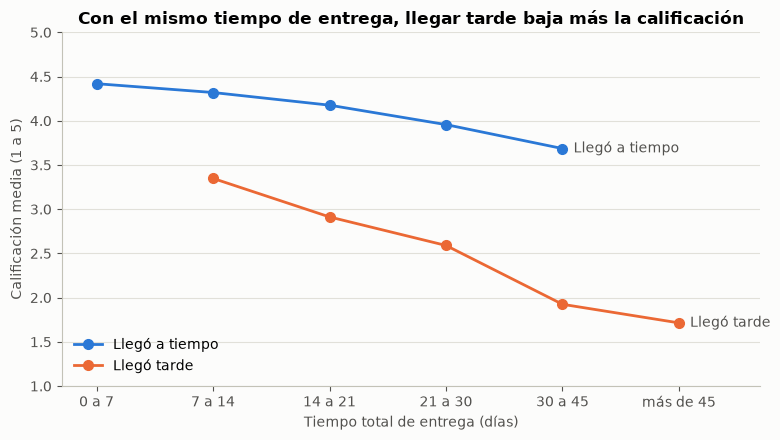

In [20]:
por_tramo = (
    calificados.groupby(["tramo_total", "tarde"], observed=True)["review_score"]
    .agg(pedidos="size", media="mean")
    .reset_index()
)
por_tramo = por_tramo[por_tramo["pedidos"] >= 100]

fig, ax = plt.subplots(figsize=(8, 4.5))
for llegada, color, nombre in [(False, COLOR_A_TIEMPO, "Llegó a tiempo"), (True, COLOR_TARDE, "Llegó tarde")]:
    serie = por_tramo[por_tramo["tarde"] == llegada]
    x = serie["tramo_total"].cat.codes
    ax.plot(x, serie["media"], marker="o", color=color, label=nombre)
    ax.annotate(nombre, (x.iloc[-1], serie["media"].iloc[-1]), xytext=(8, 0),
                textcoords="offset points", va="center", color=COLOR_TEXTO)

ax.set_xticks(range(len(etiquetas_total)), etiquetas_total)
ax.set(
    title="Con el mismo tiempo de entrega, llegar tarde baja más la calificación",
    xlabel="Tiempo total de entrega (días)",
    ylabel="Calificación media (1 a 5)",
    ylim=(1, 5),
    xlim=(-0.3, len(etiquetas_total) - 0.3),
)
ax.legend(frameon=False, loc="lower left")
plt.tight_layout()
fig.savefig(CARPETA_RESULTADOS / "figura_1_tiempo_total_y_calificacion.png", dpi=150)
plt.show()
plt.close(fig)

**Figura 1. Qué muestra.** En cada tramo de tiempo total, los pedidos que llegaron tarde (naranja) tienen una calificación media mucho menor que los que llegaron a tiempo (azul). Por ejemplo, entre 21 y 30 días: 3.96 a tiempo contra 2.59 tarde.

**Por qué importa.** La lentitud por sí sola baja la calificación poco a poco: entre los pedidos a tiempo, la media pasa de 4.42 a 3.69 entre el tramo más rápido y el de 30 a 45 días (Spearman de −0.127). El incumplimiento de la fecha prometida pesa mucho más que los días en sí.

**Limitaciones.** Solo se grafican los grupos con al menos 100 pedidos: quedan fuera los 58 pedidos tardíos de hasta 7 días y los 45 pedidos a tiempo de más de 45 días. Es una asociación: otros factores, como el producto, el vendedor o la región, pueden influir y no están controlados.

### 3.4 Días respecto de la fecha prometida

Ahora agrupamos por cuántos días antes o después de la fecha prometida llegó el pedido, y repetimos el cálculo sin las reseñas escritas antes de la entrega (decisión 7).

In [21]:
cortes_promesa = [-np.inf, -10, -5, 0, 5, 10, np.inf]
etiquetas_promesa = ["10 o más antes", "5 a 9 antes", "0 a 4 antes",
                     "1 a 5 tarde", "6 a 10 tarde", "más de 10 tarde"]
calificados["tramo_promesa"] = pd.cut(
    calificados["dias_tarde"], bins=cortes_promesa, labels=etiquetas_promesa
)

por_promesa = resumen_por(calificados, "tramo_promesa")
por_promesa_sin_previas = resumen_por(calificados[~calificados["resena_antes_entrega"]], "tramo_promesa")
display(pd.concat(
    {"todas las reseñas": por_promesa, "sin reseñas previas a la entrega": por_promesa_sin_previas},
    axis=1,
))

todas las reseñas                     \
                          pedidos media una_estrella   
tramo_promesa                                          
10 o más antes              61523  4.32         6.41   
5 a 9 antes                 20032  4.26         6.76   
0 a 4 antes                  7888  4.12         7.87   
1 a 5 tarde                  2722  2.99        33.61   
6 a 10 tarde                 1634  1.77        67.87   
más de 10 tarde              2025  1.71        69.53   

                sin reseñas previas a la entrega                     
                                         pedidos media una_estrella  
tramo_promesa                                                        
10 o más antes                           61398.0  4.32         6.40  
5 a 9 antes                              19976.0  4.26         6.74  
0 a 4 antes                               7853.0  4.12         7.84  
1 a 5 tarde                               1598.0  3.54        18.27  
6 a 10 tarde                                33.0  2.85        39.39  
más de 10 tarde                              NaN   NaN          NaN

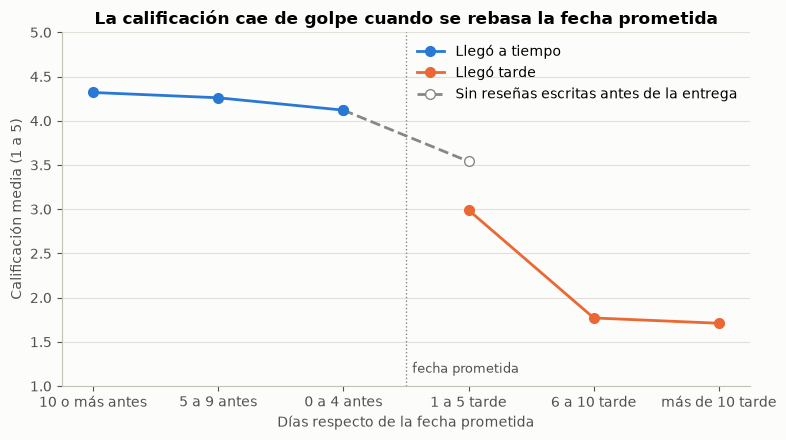

In [22]:
fig, ax = plt.subplots(figsize=(8, 4.5))
antes_de_la_promesa = por_promesa.iloc[:3]
despues_de_la_promesa = por_promesa.iloc[3:]
# Antes de la promesa las dos versiones coinciden: la gris arranca en el último punto a tiempo.
sin_previas = por_promesa_sin_previas[por_promesa_sin_previas["pedidos"] >= 100].iloc[2:]

ax.plot(antes_de_la_promesa.index.codes, antes_de_la_promesa["media"],
        marker="o", color=COLOR_A_TIEMPO, label="Llegó a tiempo", zorder=3)
ax.plot(despues_de_la_promesa.index.codes, despues_de_la_promesa["media"],
        marker="o", color=COLOR_TARDE, label="Llegó tarde", zorder=3)
ax.plot(sin_previas.index.codes, sin_previas["media"], marker="o", linestyle="--",
        color=COLOR_SECUNDARIO, markerfacecolor="white",
        label="Sin reseñas escritas antes de la entrega")
ax.axvline(2.5, color=COLOR_SECUNDARIO, linestyle=":", linewidth=1)
ax.text(2.55, 1.15, "fecha prometida", color=COLOR_TEXTO, fontsize=9)

ax.set_xticks(range(len(etiquetas_promesa)), etiquetas_promesa)
ax.set(
    title="La calificación cae de golpe cuando se rebasa la fecha prometida",
    xlabel="Días respecto de la fecha prometida",
    ylabel="Calificación media (1 a 5)",
    ylim=(1, 5),
)
ax.legend(frameon=False, loc="upper right")
plt.tight_layout()
fig.savefig(CARPETA_RESULTADOS / "figura_2_promesa_y_calificacion.png", dpi=150)
plt.show()
plt.close(fig)

**Figura 2. Qué muestra.** Mientras el pedido llega antes de la fecha prometida, la calificación casi no cambia: 4.32 si llega 10 días antes o más y 4.12 si llega entre 0 y 4 días antes. Al rebasar la fecha, cae a **2.99 con 1 a 5 días de retraso** y a cerca de 1.7 con más de 5 días.

**Por qué importa.** La satisfacción no depende tanto de cuánto tarda el pedido como de si se cumple lo prometido. La fecha prometida funciona como un umbral.

**Limitaciones.** Una parte del castigo ocurre durante la espera. Sin las reseñas escritas antes de recibir el pedido (línea gris, que arranca en el último punto a tiempo porque antes de la promesa ambas versiones coinciden), la media con 1 a 5 días de retraso sube a 3.54. Para más de 10 días de retraso **no hay ninguna reseña escrita después de la entrega**: todas se escribieron mientras el cliente esperaba. Por eso la línea gris se detiene antes; también se omiten los grupos con menos de 100 pedidos.

### 3.5 Respuesta a la pregunta 1

- **Sí hay relación:** a mayor tiempo de entrega, menor satisfacción. La calificación media baja de 4.42 a 1.78 y la proporción de una estrella sube de 5.3 % a 69 %, aunque la correlación global es débil (Spearman de −0.235) porque la mayoría de los pedidos llega rápido y bien calificado.
- **Lo que más pesa es incumplir la fecha prometida.** Con el mismo tiempo total, los pedidos tardíos califican mucho peor, y la calificación cae de golpe justo al rebasar la fecha. Entre los pedidos a tiempo, la lentitud pesa poco.
- **Buena parte de la insatisfacción se expresa durante la espera:** muchas reseñas de pedidos tardíos se escriben antes de que el pedido llegue.
- **Alcance:** es una asociación descriptiva entre pedidos entregados con reseña; no demuestra que el retraso cause la baja calificación.

## 4. Pregunta 2 · Volumen mensual de pedidos y retrasos

*¿Existe una asociación entre los meses de mayor volumen de pedidos y el incremento en los retrasos de entrega?*

Agrupamos por **mes de compra**. El **volumen** es el número de pedidos comprados en el mes, en cualquier estado, porque todos representan carga para la operación. El **retraso** es el porcentaje de los pedidos entregados de ese mes que llegaron después de la fecha prometida (decisión 4).

### 4.1 Pedidos y retrasos por mes

In [23]:
mes_compra = pedidos["order_purchase_timestamp"].dt.to_period("M")
volumen = pedidos.groupby(mes_compra).size().rename("pedidos")

retrasos = entregados.groupby(entregados["order_purchase_timestamp"].dt.to_period("M")).agg(
    entregados=("order_id", "size"),
    tardes=("tarde", "sum"),
)

mensual = volumen.to_frame().join(retrasos).fillna(0).astype(int)
mensual["pct_tarde"] = mensual["tardes"] / mensual["entregados"] * 100
mensual["pct_sin_entregar"] = (mensual["pedidos"] - mensual["entregados"]) / mensual["pedidos"] * 100
mensual.index.name = "mes_compra"
display(mensual.round(2))  # se redondea solo al mostrar

print("Días con más pedidos:")
display(pedidos["order_purchase_timestamp"].dt.date.value_counts().head(3).to_frame("pedidos"))

,pedidos,entregados,tardes,pct_tarde,pct_sin_entregar
mes_compra,,,,,
2016-09,4,1,1,100.00,75.00
2016-10,324,265,2,0.75,18.21
2016-12,1,1,0,0.00,0.00
2017-01,800,750,22,2.93,6.25
2017-02,1780,1653,49,2.96,7.13
2017-03,2682,2546,116,4.56,5.07
2017-04,2404,2303,151,6.56,4.20
2017-05,3700,3545,106,2.99,4.19
2017-06,3245,3135,95,3.03,3.39


Días con más pedidos:


,pedidos
order_purchase_timestamp,
2017-11-24,1176
2017-11-25,499
2017-11-27,403


**Lo que muestra la tabla**

- Los extremos del registro están incompletos: 2016 tiene meses con 4, 324 y 1 pedidos (y ninguno en noviembre), y los últimos meses (septiembre y octubre de 2018) tienen 16 y 4 pedidos, ninguno entregado, porque los datos terminan el 17 de octubre de 2018.
- Entre enero de 2017 y agosto de 2018 hay **20 meses consecutivos**, todos con al menos 800 pedidos.
- Al final de ese periodo no se ve que falten pedidos todavía en camino: el porcentaje sin entregar en junio a agosto de 2018 (1.2 % a 2.5 %) no es mayor que en los meses anteriores. Si fuera mayor, el retraso de esos meses estaría subestimado, porque los pedidos tardíos aún en camino no aparecerían como entregados.
- El día con más pedidos fue el **24 de noviembre de 2017**, el Black Friday de ese año.

**Decisión 8.** Analizamos de enero de 2017 a agosto de 2018. Los meses de los extremos tienen muy pocos pedidos y su porcentaje de retraso no sería comparable.

In [24]:
periodo = mensual.loc["2017-01":"2018-08"].copy()
print("Meses analizados:", len(periodo))
print("Pedidos por mes: mínimo", periodo["pedidos"].min(), "y máximo", periodo["pedidos"].max())

registrar_decision(
    "Decisión 8", "orders", "meses incompletos al inicio (2016) y al final (sep-oct 2018)",
    mensual["pedidos"].sum() - periodo["pedidos"].sum(),
    "analizar de enero 2017 a agosto 2018 (20 meses)",
    "solo hay un noviembre y un periodo de 20 meses",
)

Meses analizados: 20
Pedidos por mes: mínimo 800 y máximo 7544


### 4.2 ¿Los meses con más pedidos tienen más retrasos?

Medimos la asociación de tres formas: la correlación de Spearman entre pedidos y porcentaje de retraso de cada mes, el retraso de los 5 meses con más pedidos contra el resto, y la correlación entre los **cambios** de un mes a otro. La última responde algo distinto: si cuando el volumen sube de un mes al siguiente, el retraso también sube.

In [25]:
rho_mensual = periodo[["pedidos", "pct_tarde"]].corr(method="spearman").iloc[0, 1]
print(f"Spearman entre pedidos del mes y % de retrasos ({len(periodo)} meses): {rho_mensual:.3f}")

mas_volumen = periodo["pedidos"].nlargest(5).index
resto = periodo.drop(mas_volumen)
comparacion = pd.DataFrame({
    "meses": [len(mas_volumen), len(resto)],
    "pct_tarde": [
        periodo.loc[mas_volumen, "tardes"].sum() / periodo.loc[mas_volumen, "entregados"].sum() * 100,
        resto["tardes"].sum() / resto["entregados"].sum() * 100,
    ],
}, index=["5 meses con más pedidos", "resto de los meses"]).round(2)
display(comparacion)
print("Meses con más pedidos:", ", ".join(str(mes) for mes in mas_volumen))

cambios = periodo[["pedidos", "pct_tarde"]].diff().dropna()
rho_cambios = cambios.corr(method="spearman").iloc[0, 1]
print(f"Spearman entre los cambios de un mes a otro: {rho_cambios:.3f}")

Spearman entre pedidos del mes y % de retrasos (20 meses): 0.568


,meses,pct_tarde
5 meses con más pedidos,5,9.69
resto de los meses,15,5.13


Meses con más pedidos: 2017-11, 2018-01, 2018-03, 2018-04, 2018-05
Spearman entre los cambios de un mes a otro: 0.104


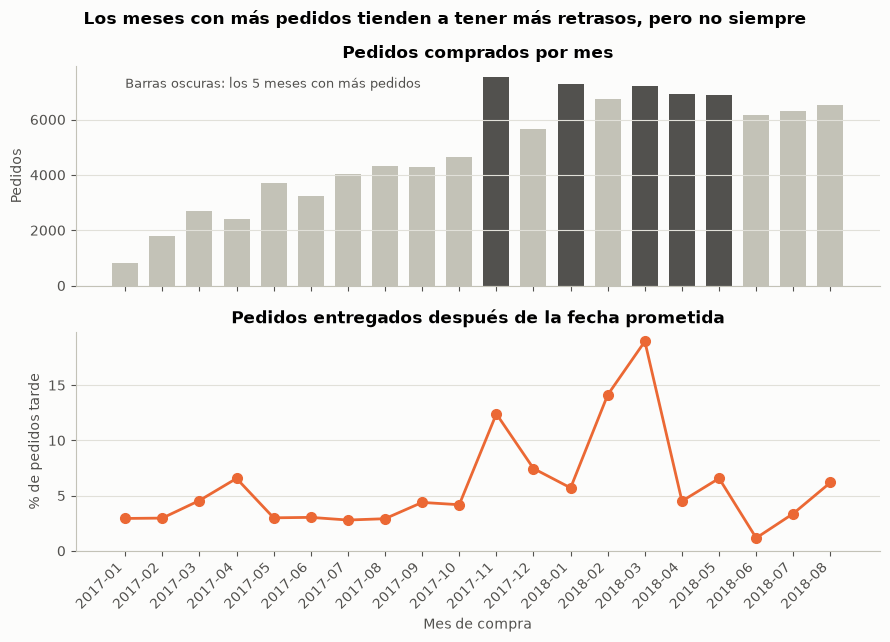

In [26]:
x = range(len(periodo))
colores_barras = [COLOR_TEXTO if mes in mas_volumen else "#c3c2b7" for mes in periodo.index]

fig, (ax_pedidos, ax_tarde) = plt.subplots(2, 1, figsize=(9, 6.5), sharex=True)
ax_pedidos.bar(x, periodo["pedidos"], color=colores_barras, width=0.7)
ax_pedidos.set(title="Pedidos comprados por mes", ylabel="Pedidos")
ax_pedidos.text(0, periodo["pedidos"].max(), "Barras oscuras: los 5 meses con más pedidos",
                color=COLOR_TEXTO, fontsize=9, va="top")

ax_tarde.plot(x, periodo["pct_tarde"], marker="o", color=COLOR_TARDE)
ax_tarde.set(title="Pedidos entregados después de la fecha prometida",
             ylabel="% de pedidos tarde", xlabel="Mes de compra", ylim=(0, None))
ax_tarde.set_xticks(list(x), periodo.index.astype(str), rotation=45, ha="right")

fig.suptitle("Los meses con más pedidos tienden a tener más retrasos, pero no siempre", fontweight="bold")
plt.tight_layout()
fig.savefig(CARPETA_RESULTADOS / "figura_3_pedidos_y_retrasos_por_mes.png", dpi=150)
plt.show()
plt.close(fig)

**Figura 3. Qué muestra.** Arriba, los pedidos de cada mes; abajo, el porcentaje de pedidos que llegaron tarde, con el mismo eje de meses. Usamos dos paneles y no un solo gráfico con dos ejes verticales, porque las dos medidas tienen escalas distintas.

**Por qué importa.** El mes con más pedidos, **noviembre de 2017** (7,544, con el Black Friday), coincide con un salto del retraso a 12.4 %. Pero los peores meses son **febrero y marzo de 2018** (14.1 % y 19.0 %), que no fueron los de más pedidos. En cambio, **junio de 2018** tuvo 6,167 pedidos y solo 1.2 % de retrasos.

**Limitaciones.** El volumen crece a lo largo del tiempo, así que la figura mezcla dos cosas: el volumen y todo lo demás que cambió en esos meses (capacidad de transporte, vendedores, fechas prometidas). Solo hay un noviembre en el periodo, así que no podemos confirmar que el patrón se repita cada año.

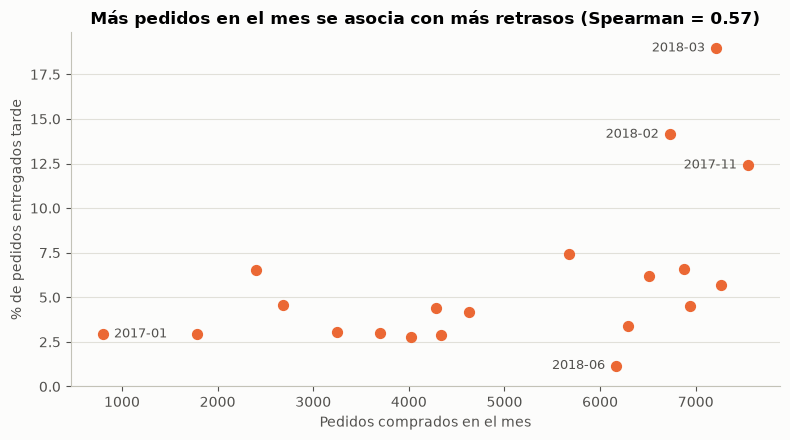

In [27]:
fig, ax = plt.subplots(figsize=(8, 4.5))
ax.scatter(periodo["pedidos"], periodo["pct_tarde"], color=COLOR_TARDE, s=50, zorder=3)

destacados = {
    "2017-01": (8, "left"),
    "2017-11": (-8, "right"),
    "2018-02": (-8, "right"),
    "2018-03": (-8, "right"),
    "2018-06": (-8, "right"),
}
for mes, (desplazamiento, alineacion) in destacados.items():
    fila = periodo.loc[mes]
    ax.annotate(mes, (fila["pedidos"], fila["pct_tarde"]), xytext=(desplazamiento, 0),
                textcoords="offset points", ha=alineacion, va="center",
                color=COLOR_TEXTO, fontsize=9)

ax.set(
    title=f"Más pedidos en el mes se asocia con más retrasos (Spearman = {rho_mensual:.2f})",
    xlabel="Pedidos comprados en el mes",
    ylabel="% de pedidos entregados tarde",
    ylim=(0, None),
)
plt.tight_layout()
fig.savefig(CARPETA_RESULTADOS / "figura_4_volumen_contra_retrasos.png", dpi=150)
plt.show()
plt.close(fig)

**Figura 4. Qué muestra.** Cada punto es un mes: a la derecha, los meses con más pedidos; arriba, los meses con más retrasos. Los meses de menos volumen (2017) se concentran abajo a la izquierda y los de más retraso están todos a la derecha.

**Por qué importa.** Ningún mes con menos de 5,000 pedidos superó el 7 % de retrasos, pero entre los meses con más de 6,000 pedidos hay de todo: desde 1.2 % hasta 19.0 %. Un volumen alto parece una condición para que haya muchos retrasos, pero no basta para causarlos.

**Limitaciones.** Son solo 20 puntos y no se ajusta ninguna recta, porque la relación no es lineal ni estable. La correlación describe meses, no pedidos individuales.

### 4.3 Respuesta a la pregunta 2

- **Sí hay una asociación positiva y moderada** entre el volumen mensual y los retrasos: Spearman de 0.57 en 20 meses. En los 5 meses con más pedidos, el 9.7 % de los pedidos entregados llegó tarde, contra 5.1 % en el resto.
- **No es una relación mes a mes:** cuando el volumen sube de un mes al siguiente, el retraso no sube necesariamente (Spearman de los cambios de 0.10).
- **El ejemplo más claro es noviembre de 2017**, con el récord de pedidos (y su día pico, el Black Friday) y 12.4 % de retrasos. Pero el peor periodo, febrero y marzo de 2018, no fue el de más pedidos, y junio de 2018 tuvo mucho volumen y casi ningún retraso.
- **Alcance:** el volumen alto acompaña a los retrasos, pero no los explica por sí solo. Con 20 meses y una tendencia de crecimiento, no podemos separar el efecto del volumen de otros cambios en el tiempo.